# Assignment 8: Exploratory Data Analysis (EDA)

| | |
|---|---|
| **Student** | Lokesh Patwal |
| **Programme** | Yuva Intern - Data Science Fundamentals Assessment |
| **Assignment** | 8 of 10 |

## 2. Aim
To explore a real dataset systematically (structure, distributions, relationships, patterns) and to draw conclusions that are supported by numbers and charts.

## 3. Objectives
1. Understand the structure and quality of a dataset.
2. Calculate descriptive statistics.
3. Perform univariate analysis (one variable at a time).
4. Perform bivariate analysis (two variables, and a variable by group).
5. Study correlations, including inside each group.
6. Test whether group differences are statistically significant.
7. State conclusions and their limits.

## 4. Introduction and Theory
**EDA** (John Tukey, 1977) means looking at data *before* modelling: summarise it, plot it, find patterns and surprises, and check assumptions.

* **Univariate:** histogram, box plot, summary numbers for one column.
* **Bivariate:** scatter plot and correlation for two numeric columns; box plots for a number by category.
* **Correlation (r):** -1 to +1, linear association. **Simpson-type effects:** a relationship that looks strong overall can be weaker (or different) inside each group.
* **One-way ANOVA** tests whether group means differ; **effect size (eta squared)** tells *how much* of the variation the groups explain. A tiny p-value alone does not say the difference is large.

## 5. Software and Libraries Required
Python 3, pandas, NumPy, Matplotlib, Seaborn, SciPy, scikit-learn (to load Iris), `src/ds_helpers.py`.

## 6. Dataset Details
**Iris** (R. A. Fisher, 1936; UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/53/iris). 150 flowers, 3 species (setosa, versicolor, virginica), 50 each. Columns: `sepal_length`, `sepal_width`, `petal_length`, `petal_width` (all in cm) and `species`. It is small, clean and has clear group structure, which makes the EDA ideas easy to see. It is a *measurement* dataset about flowers, with no personal data.

## 7. Step-by-Step Procedure
1. Understand the data. 2. Descriptive statistics. 3. Univariate analysis. 4. Bivariate analysis. 5. Correlation (overall and within species). 6. Significance and effect size. 7. Conclusions.

## 8. Complete Python Code and 9. Expected Output
The output under each code cell is the actual output produced when this notebook was executed.

### Step 1: Understand the data

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_iris

sys.path.insert(0, str(Path("..").resolve()))
from src import ds_helpers as h

sns.set_theme(style="whitegrid")
Path("../visualizations").mkdir(exist_ok=True)

bunch = load_iris(as_frame=True)
iris = bunch.data.copy()
iris.columns = [c.replace(" (cm)", "").replace(" ", "_") for c in iris.columns]
iris["species"] = pd.Categorical(bunch.target_names[bunch.target], categories=list(bunch.target_names))
measures = [c for c in iris.columns if c != "species"]

print("Shape:", iris.shape)
display(iris.sample(5, random_state=42))
iris.info()
print("Missing values:", int(iris.isna().sum().sum()), "| duplicate rows:", int(iris.duplicated().sum()))
print(iris["species"].value_counts().to_string())

Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
73,6.1,2.8,4.7,1.2,versicolor
18,5.7,3.8,1.7,0.3,setosa
118,7.7,2.6,6.9,2.3,virginica
78,6.0,2.9,4.5,1.5,versicolor
76,6.8,2.8,4.8,1.4,versicolor


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   sepal_length  150 non-null    float64 
 1   sepal_width   150 non-null    float64 
 2   petal_length  150 non-null    float64 
 3   petal_width   150 non-null    float64 
 4   species       150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB
Missing values: 0 | duplicate rows: 1
species
setosa        50
versicolor    50
virginica     50


### Step 2: Descriptive statistics

In [2]:
display(h.describe_numeric(iris[measures]).round(3))
display(iris.groupby("species", observed=True)[measures].mean().round(3))

,count,mean,median,variance,std,min,q1,q3,max,iqr
sepal_length,150,5.843,5.80,0.686,0.828,4.3,5.1,6.4,7.9,1.3
sepal_width,150,3.057,3.00,0.190,0.436,2.0,2.8,3.3,4.4,0.5
petal_length,150,3.758,4.35,3.116,1.765,1.0,1.6,5.1,6.9,3.5
petal_width,150,1.199,1.30,0.581,0.762,0.1,0.3,1.8,2.5,1.5


,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


### Step 3: Univariate analysis

IQR outliers per column: {'sepal_length': 0, 'sepal_width': 4, 'petal_length': 0, 'petal_width': 0}


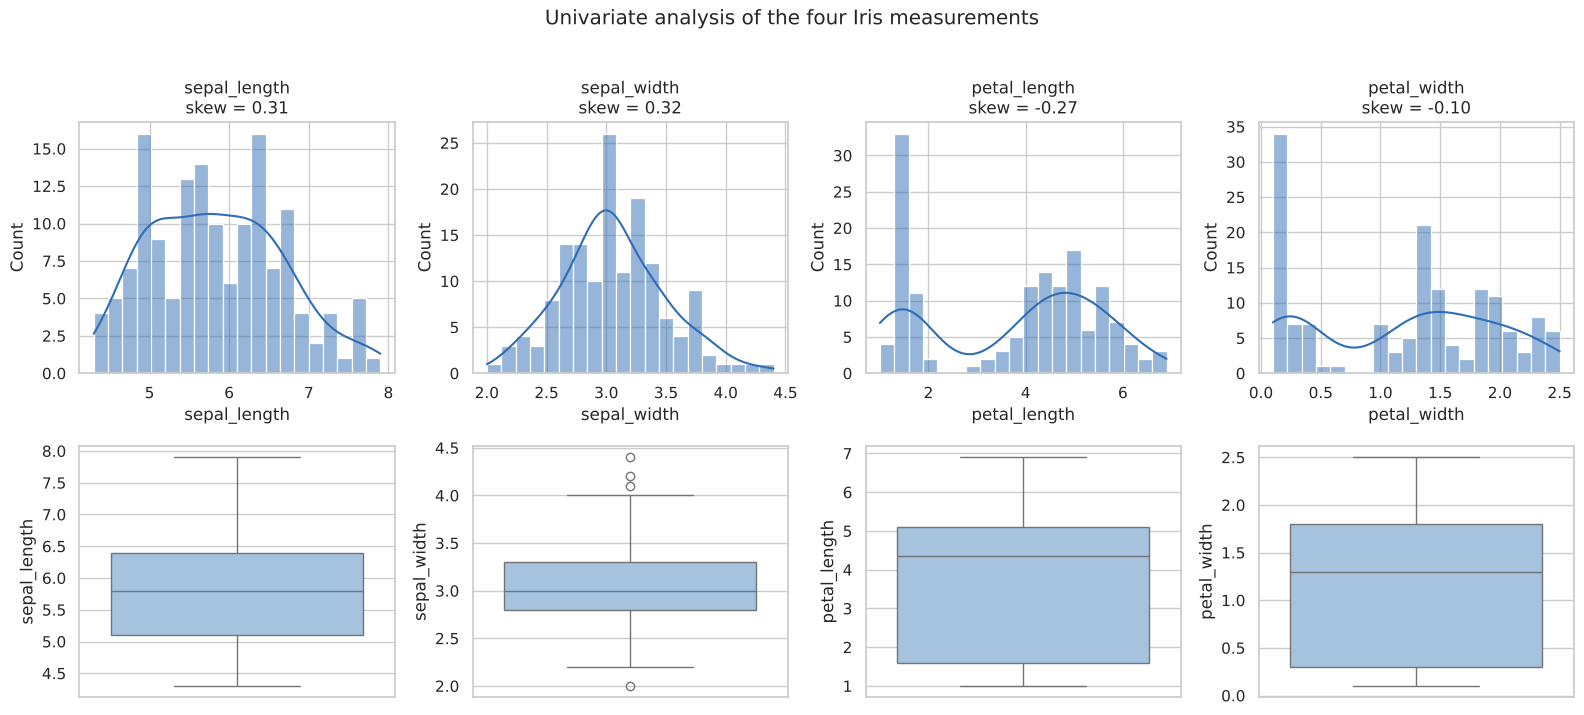

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, column in enumerate(measures):
    sns.histplot(iris[column], kde=True, bins=20, color="#2F6DB5", ax=axes[0, i])
    axes[0, i].set_title(f"{column}\nskew = {iris[column].skew():.2f}")
    sns.boxplot(y=iris[column], color="#9CC3E8", ax=axes[1, i])
fig.suptitle("Univariate analysis of the four Iris measurements", y=1.02)
fig.tight_layout()
fig.savefig("../visualizations/a8_univariate.png", dpi=150, bbox_inches="tight")
plt.show()

outlier_counts = {c: int(h.iqr_outlier_mask(iris[c]).sum()) for c in measures}
print("IQR outliers per column:", outlier_counts)

The petal columns look *bimodal* (two humps): setosa has very small petals, the other two species larger ones. A single overall mean would describe nobody well, which is why we look at groups next.

### Step 4: Bivariate analysis

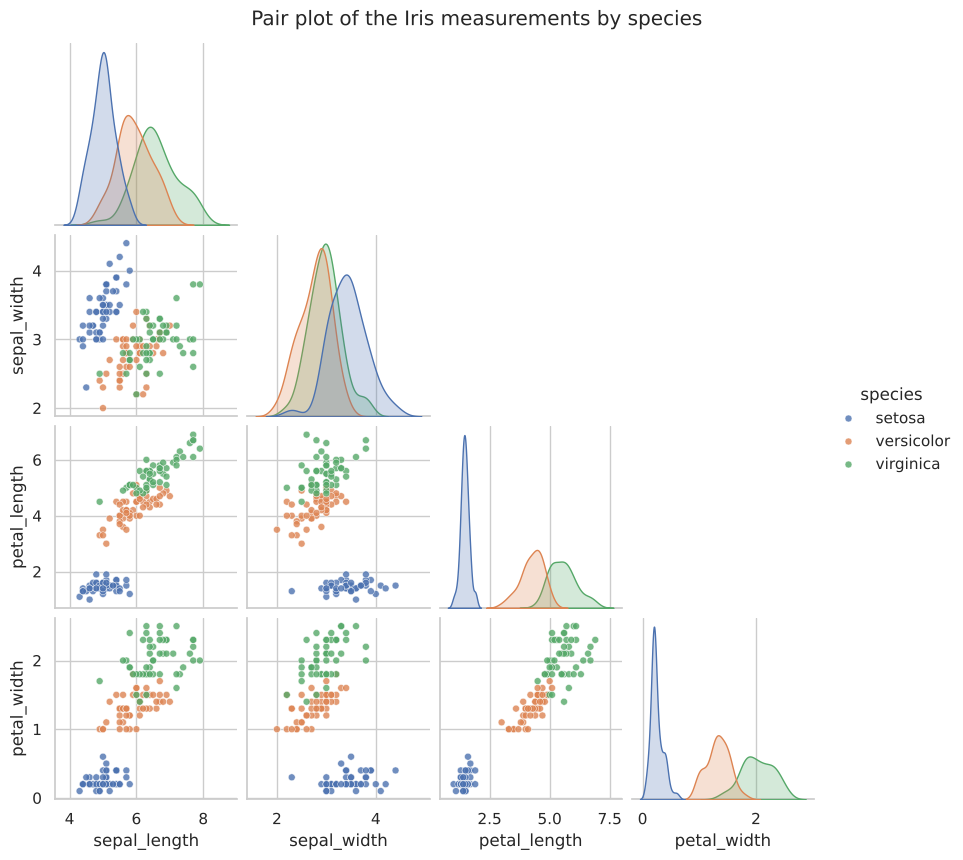

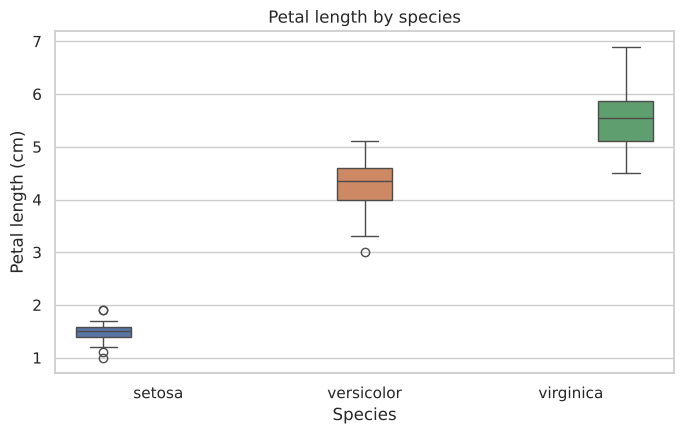

In [4]:
g = sns.pairplot(iris, hue="species", corner=True, plot_kws={"s": 25, "alpha": 0.8}, height=2.1)
g.figure.suptitle("Pair plot of the Iris measurements by species", y=1.02)
g.savefig("../visualizations/a8_pairplot.png", dpi=130)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=iris, x="species", y="petal_length", hue="species", legend=False, ax=ax)
ax.set(title="Petal length by species", xlabel="Species", ylabel="Petal length (cm)")
fig.tight_layout()
fig.savefig("../visualizations/a8_petal_length_by_species.png", dpi=150)
plt.show()

### Step 5: Correlation - overall and inside each species

,"r(petal_length, petal_width)","r(sepal_length, sepal_width)"
group,,
ALL FLOWERS,0.963,-0.118
setosa,0.332,0.743
versicolor,0.787,0.526
virginica,0.322,0.457


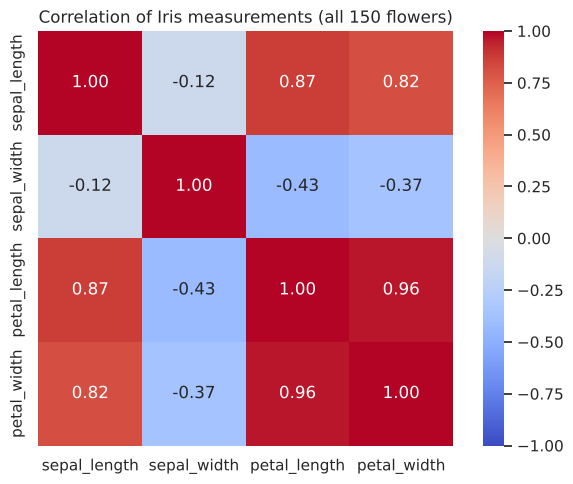

In [5]:
overall = iris[measures].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(overall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation of Iris measurements (all 150 flowers)")
fig.tight_layout()
fig.savefig("../visualizations/a8_correlation_heatmap.png", dpi=150)
plt.show()

rows = []
for species_name, part in iris.groupby("species", observed=True):
    rows.append({"group": species_name, "r(petal_length, petal_width)": part["petal_length"].corr(part["petal_width"]),
                 "r(sepal_length, sepal_width)": part["sepal_length"].corr(part["sepal_width"])})
rows.insert(0, {"group": "ALL FLOWERS", "r(petal_length, petal_width)": overall.loc["petal_length", "petal_width"],
                "r(sepal_length, sepal_width)": overall.loc["sepal_length", "sepal_width"]})
within = pd.DataFrame(rows).set_index("group").round(3)
display(within)

Notice that the overall sepal length-width correlation is -0.12 (slightly negative), while inside every species it is positive ([0.743, 0.526, 0.457]). Mixing groups can hide or even reverse the pattern inside each group.

### Step 6: Are the group differences statistically meaningful?

In [6]:
groups = [iris.loc[iris["species"] == s, "petal_length"].to_numpy() for s in iris["species"].cat.categories]
f_stat, p_value = stats.f_oneway(*groups)
eta2 = h.eta_squared(groups)
h_stat, p_kw = stats.kruskal(*groups)
print(f"ANOVA on petal length : F = {f_stat:.1f}, p = {p_value:.2e}")
print(f"Kruskal-Wallis (no normality assumption): H = {h_stat:.1f}, p = {p_kw:.2e}")
print(f"Effect size eta squared = {eta2:.3f}  ({eta2 * 100:.1f}% of the variation is explained by species)")

d_setosa_versi = h.cohens_d(groups[0], groups[1])
d_versi_virg = h.cohens_d(groups[1], groups[2])
print(f"Cohen's d setosa vs versicolor: {d_setosa_versi:.2f} | versicolor vs virginica: {d_versi_virg:.2f}")

ANOVA on petal length : F = 1180.2, p = 2.86e-91
Kruskal-Wallis (no normality assumption): H = 130.4, p = 4.80e-29
Effect size eta squared = 0.941  (94.1% of the variation is explained by species)
Cohen's d setosa vs versicolor: -7.90 | versicolor vs virginica: -2.52


### Step 7: Validation checks

In [7]:
assert iris.shape == (150, 5) and iris.isna().sum().sum() == 0
assert abs(overall.loc["petal_length", "petal_width"] - np.corrcoef(iris["petal_length"], iris["petal_width"])[0, 1]) < 1e-12
assert 0 <= eta2 <= 1 and p_value < 0.001 and p_kw < 0.001
assert Path("../visualizations/a8_pairplot.png").stat().st_size > 10_000
print("All validation checks passed.")

All validation checks passed.


## 10. Output Explanation
* **Structure:** `150` flowers x `5` columns, `0` missing values, `1` duplicated row(s) and exactly 50 flowers per species.
* **Univariate:** the IQR rule flags only `4` extreme value(s) in total (`{'sepal_length': 0, 'sepal_width': 4, 'petal_length': 0, 'petal_width': 0}`), all in sepal width; petal length and petal width show two clusters, not one bell.
* **Bivariate:** in the pair plot setosa (blue) is completely separate from the others on the petal measurements, while versicolor and virginica overlap a little.
* **Correlation:** over all flowers petal length and petal width correlate at `0.96`, but inside each species the correlations are much lower (`[0.33, 0.79, 0.32]` for setosa, versicolor, virginica). Much of the overall strength comes from the *differences between species*.
* **Significance:** ANOVA gives p = `2.9e-91` and eta squared = `0.94`, so species explains `94`% of the variation in petal length. Both the test and the effect size say the difference is real and large. The rank-based Kruskal-Wallis test agrees.

## 11. Observations and Analysis
* **Key insight 1:** petal measurements separate the species far better than sepal measurements.
* **Key insight 2:** overall correlations can overstate the relationship inside groups, so always check by group.
* **Key insight 3:** statistical significance (tiny p-value) and practical size (eta squared, Cohen's d) are different ideas; report both.
* **Limitations:** Iris is a small, clean, textbook dataset (150 flowers from one study). Findings describe these flowers and may not generalise. EDA shows associations, not causes.

**Common mistakes**
| Mistake | Fix |
|---|---|
| Looking only at averages | Plot the distribution too |
| Ignoring group structure | Compare by group and check within-group correlations |
| Calling a tiny p-value "important" | Also report the effect size |

**Practice tasks**
1. Repeat the within-group correlation table for sepal length and petal length.
2. Which pair of species is hardest to separate using petal width alone?
3. Write three sentences describing the Iris data for a non-technical reader.

## 12. Result / Conclusion
EDA showed that the three Iris species differ strongly in petal size, that the data contain no missing values and almost no outliers, and that group-wise analysis gives a more honest picture than overall correlations. All numbers were computed in the notebook and all validation checks passed.